### Ad Click prediction - Data preprocessing & cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Upskill\Data Science\ML - Project\Ad Click prediction\data\ad_10000records.csv")

In [3]:
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Gender,Country,Timestamp,Clicked on Ad
0,62.26,32.0,69481.85,172.83,Decentralized real-time circuit,Lisafort,Male,Svalbard & Jan Mayen Islands,2016-06-09 21:43:05,0
1,41.73,31.0,61840.26,207.17,Optional full-range projection,West Angelabury,Male,Singapore,2016-01-16 17:56:05,0
2,44.40,30.0,57877.15,172.83,Total 5thgeneration standardization,Reyesfurt,Female,Guadeloupe,2016-06-29 10:50:45,0
3,59.88,28.0,56180.93,207.17,Balanced empowering success,New Michael,Female,Zambia,2016-06-21 14:32:32,0
4,49.21,30.0,54324.73,201.58,Total 5thgeneration standardization,West Richard,Female,Qatar,2016-07-21 10:54:35,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  10000 non-null  float64
 1   Age                       10000 non-null  float64
 2   Area Income               10000 non-null  float64
 3   Daily Internet Usage      10000 non-null  float64
 4   Ad Topic Line             10000 non-null  object 
 5   City                      10000 non-null  object 
 6   Gender                    10000 non-null  object 
 7   Country                   10000 non-null  object 
 8   Timestamp                 10000 non-null  object 
 9   Clicked on Ad             10000 non-null  int64  
dtypes: float64(4), int64(1), object(5)
memory usage: 781.4+ KB


In [5]:
df.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Clicked on Ad
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,61.660757,35.940100,53840.047721,177.759831,0.491700
std,15.704142,8.572973,13343.708718,40.820951,0.499956
min,32.600000,19.000000,13996.500000,105.220000,0.000000
25%,48.860000,29.000000,44052.302500,140.150000,0.000000
50%,59.590000,35.000000,56180.930000,178.920000,0.000000
75%,76.580000,42.000000,61840.260000,212.670000,1.000000
max,90.970000,60.000000,79332.330000,269.960000,1.000000


In [6]:
df.select_dtypes(include=[np.number]).median()

Daily Time Spent on Site       59.59
Age                            35.00
Area Income                 56180.93
Daily Internet Usage          178.92
Clicked on Ad                   0.00
dtype: float64

In [7]:
df.columns

Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Ad Topic Line', 'City', 'Gender', 'Country',
       'Timestamp', 'Clicked on Ad'],
      dtype='object')

In [8]:
# drop the columns which are not required for analysis
df.drop(columns=["Ad Topic Line"], axis=1, inplace=True)
# df.drop(columns=["Timestamp"],axis=1,inplace=True)
df.drop(columns=["City"],axis=1,inplace=True)
df.drop(columns=["Country"],axis=1,inplace=True)

In [9]:
df.rename(columns={'Daily Time Spent on Site': 'Time on Site'}, inplace=True)

In [14]:
df.head()

,Time on Site,Age,Area Income,Daily Internet Usage,Gender,Clicked on Ad,Hour,Day,Month,DayOfWeek
0,62.26,32.0,69481.85,172.83,Male,0,21,9,6,3
1,41.73,31.0,61840.26,207.17,Male,0,17,16,1,5
2,44.40,30.0,57877.15,172.83,Female,0,10,29,6,2
3,59.88,28.0,56180.93,207.17,Female,0,14,21,6,1
4,49.21,30.0,54324.73,201.58,Female,1,10,21,7,3


In [11]:
df['Gender'].value_counts()

Gender
Female    5376
Male      4624
Name: count, dtype: int64

In [44]:
df.isnull().sum()

Time on Site            0
Age                     0
Area Income             0
Daily Internet Usage    0
Gender                  0
Clicked on Ad           0
dtype: int64

In [47]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)

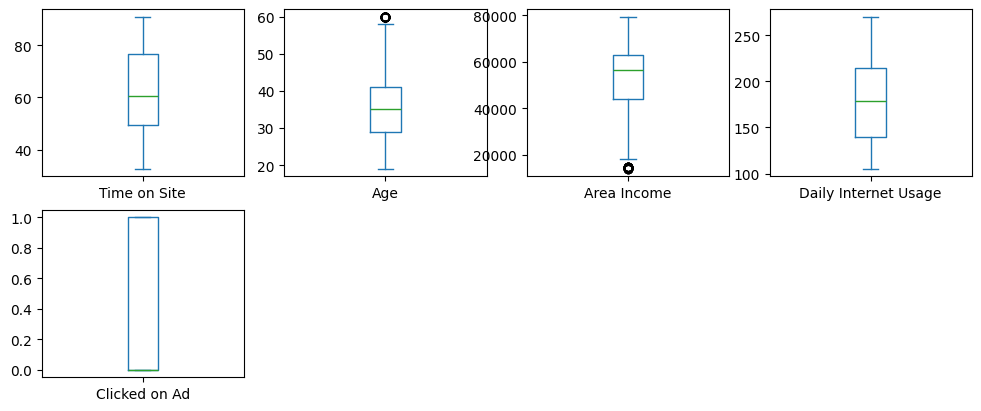

In [52]:
df.plot(kind='box', subplots=True, layout=(4,4), figsize=(12,10))
plt.show()

In [12]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

In [13]:
df.drop(columns=['Timestamp'], inplace=True)

In [15]:
df.to_csv(r"C:\Upskill\Data Science\ML - Project\Ad Click prediction\data\cleaned_ad_10000records.csv", index=False)